<a href="https://colab.research.google.com/github/dbonjd007/ds-core-projects/blob/main/anomaly-detection/M7_Assignment_Anomaly_Detection_%26_Fraud_Prevention_Assessment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 1. Load Dataset

### Subtask:
Load the `data.csv` file into a pandas DataFrame to begin the analysis.


**Reasoning**:
First, I'll import the pandas library to work with DataFrames, then load the `data.csv` file into a DataFrame named `df` and display its head to verify the import and loading process.



In [ ]:
import pandas as pd
df = pd.read_csv('/content/data.csv', encoding='latin1')
print(df.head())

  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                  WHITE METAL LANTERN         6   
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

      InvoiceDate  UnitPrice  CustomerID         Country  
0  12/1/2010 8:26       2.55     17850.0  United Kingdom  
1  12/1/2010 8:26       3.39     17850.0  United Kingdom  
2  12/1/2010 8:26       2.75     17850.0  United Kingdom  
3  12/1/2010 8:26       3.39     17850.0  United Kingdom  
4  12/1/2010 8:26       3.39     17850.0  United Kingdom  


## 2. Inspect Data and Select Features

### Subtask:
Examine the loaded dataset to understand its structure, identify potential issues, and select the most relevant numerical features for anomaly detection. This may involve checking for missing values, data types, and initial distributions.


**Reasoning**:
To understand the dataset's structure, data types, and identify missing values, I will display a concise summary, descriptive statistics, and the count of missing values for each column. This will help in selecting appropriate numerical features for anomaly detection.



In [ ]:
print(df.info())
print("\nDescriptive Statistics:\n")
print(df.describe())
print("\nMissing Values:\n")
print(df.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  object 
 2   Description  540455 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 33.1+ MB
None

Descriptive Statistics:

            Quantity      UnitPrice     CustomerID
count  541909.000000  541909.000000  406829.000000
mean        9.552250       4.611114   15287.690570
std       218.081158      96.759853    1713.600303
min    -80995.000000  -11062.060000   12346.000000
25%         1.000000       1.250000   13953.000000
50%         3.000000       2.080000   15152.000000
75%      

**Reasoning**:
Based on the data's descriptive statistics and types, 'Quantity' and 'UnitPrice' are clearly numerical and directly relevant to transactional anomalies. 'CustomerID' has a significant number of missing values and might not be a suitable feature for direct anomaly detection without further imputation or feature engineering. Therefore, I will select 'Quantity' and 'UnitPrice' as the features for anomaly detection.



In [ ]:
features = ['Quantity', 'UnitPrice']
df_numerical = df[features]
print(f"Selected numerical features for anomaly detection: {features}")
print(df_numerical.head())

Selected numerical features for anomaly detection: ['Quantity', 'UnitPrice']
   Quantity  UnitPrice
0         6       2.55
1         6       3.39
2         8       2.75
3         6       3.39
4         6       3.39


## 3. Apply Anomaly Detection

### Subtask:
Apply an anomaly detection technique, such as Isolation Forest, to the selected features.


**Reasoning**:
To apply anomaly detection, I will import the `IsolationForest` model, instantiate it with a specified `random_state` and `contamination` rate, fit it to the `df_numerical` DataFrame, and then predict and store both the anomaly scores and labels in new columns within the original `df` DataFrame.



In [ ]:
from sklearn.ensemble import IsolationForest

# Instantiate IsolationForest model
# Using contamination=0.01 as a reasonable estimate for anomaly proportion
# random_state for reproducibility
model = IsolationForest(random_state=42, contamination=0.01)

# Fit the model to the numerical data
model.fit(df_numerical)

# Predict anomaly scores and labels
df['anomaly_score'] = model.decision_function(df_numerical)
df['anomaly_label'] = model.predict(df_numerical)

print("Anomaly detection applied. New columns 'anomaly_score' and 'anomaly_label' added to df.")
print(df[['Quantity', 'UnitPrice', 'anomaly_score', 'anomaly_label']].head())

Anomaly detection applied. New columns 'anomaly_score' and 'anomaly_label' added to df.
   Quantity  UnitPrice  anomaly_score  anomaly_label
0         6       2.55       0.332658              1
1         6       3.39       0.322431              1
2         8       2.75       0.310064              1
3         6       3.39       0.322431              1
4         6       3.39       0.322431              1


## 4. Identify and Label Anomalies

### Subtask:
Based on the anomaly detection model's output, identify and label transactions as 'anomalous' or 'normal'. This will involve adding a new column to the DataFrame indicating the anomaly status of each transaction.


**Reasoning**:
To clearly identify anomalies, I will map the numerical `anomaly_label` (-1 for anomaly, 1 for normal) to descriptive string labels ('Anomaly', 'Normal') in a new column `anomaly_description`. Then, I will display the relevant columns to verify the new labels and count the total number of anomalies and normal data points to summarize the detection results.



In [ ]:
df['anomaly_description'] = df['anomaly_label'].apply(lambda x: 'Anomaly' if x == -1 else 'Normal')

print("DataFrame with anomaly descriptions:")
print(df[['Quantity', 'UnitPrice', 'anomaly_score', 'anomaly_label', 'anomaly_description']].head())

print("\nAnomaly and Normal counts:")
print(df['anomaly_description'].value_counts())

DataFrame with anomaly descriptions:
   Quantity  UnitPrice  anomaly_score  anomaly_label anomaly_description
0         6       2.55       0.332658              1              Normal
1         6       3.39       0.322431              1              Normal
2         8       2.75       0.310064              1              Normal
3         6       3.39       0.322431              1              Normal
4         6       3.39       0.322431              1              Normal

Anomaly and Normal counts:
anomaly_description
Normal     536546
Anomaly      5363
Name: count, dtype: int64


## 5. Visualize Anomalies

### Subtask:
Create a visualization, such as a scatter plot of two key features with anomalies highlighted in a distinct color, to visually represent the identified anomalous transactions. Ensure all plots have appropriate legends and labels.


**Reasoning**:
To visualize the identified anomalies, I will create a scatter plot using 'Quantity' and 'UnitPrice' as features, differentiating normal and anomalous points with distinct colors based on the 'anomaly_description' column, and ensure proper labeling and a legend for clarity.



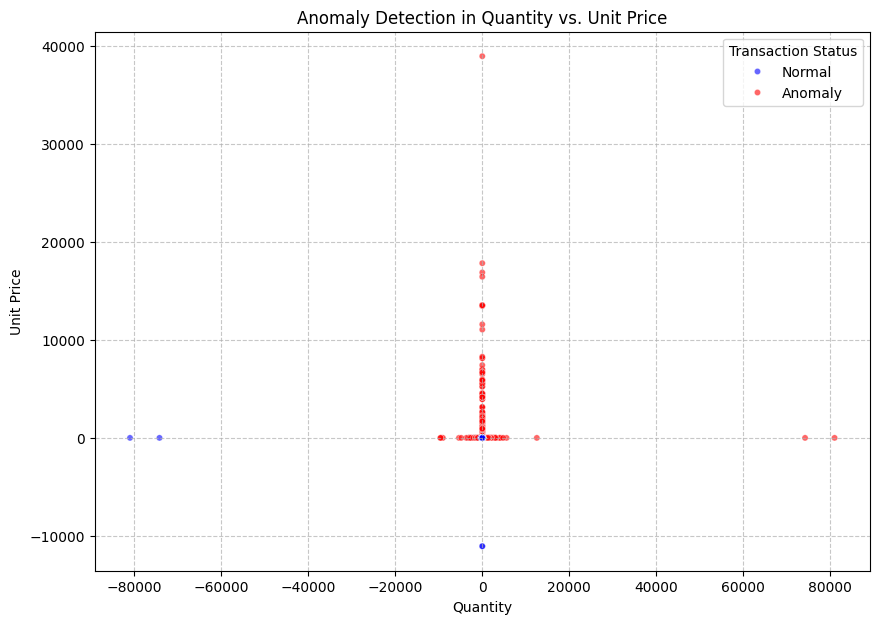

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 7))
sns.scatterplot(data=df, x='Quantity', y='UnitPrice', hue='anomaly_description', palette={'Normal': 'blue', 'Anomaly': 'red'}, s=20, alpha=0.6)
plt.title('Anomaly Detection in Quantity vs. Unit Price')
plt.xlabel('Quantity')
plt.ylabel('Unit Price')
plt.legend(title='Transaction Status')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()
